# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [6]:
patients = pd.read_csv(PATIENTS_PATH)

print(patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color("program:N"),
        shape=alt.Shape("program:N"),
        tooltip=[
            "patient_id",
            "program",
            "sessions_attended",
            "walk_distance_m"
        ]
    )
    .properties(
        title="Rehabilitation attendance and walking distance"
    )
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

display(exploratory_chart)

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

TODO: Replace this line with a few sentences: the question the chart explores, what one point represents, one pattern you see, and why twelve patients cannot show that attending more sessions causes a longer walk. The scatter plot explores whether patients who attended more cardiac rehabilitation sessions seemed to walk a larger distance during the 6 minute walking test at the end of rehabilitation, and if the relationship differed between programs. One point represents one patient and shows the number of sessions threy attended and how far they walked. One pattern seen is the positive relationship between patients who attend more sessions and larger walking distance. The 12 patients cannot show that attending more sessions causes a longer walk due to the small sample size of only 12 patients, and other potential factors such as the patients' baseline health.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


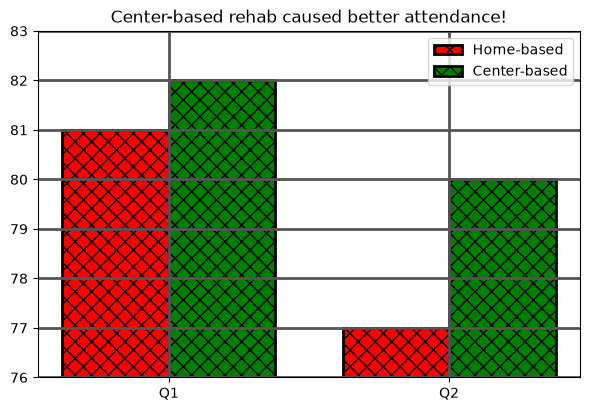

In [7]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [8]:
critique = [
    {"category": "unsupported claim", 
    "problem": "The graph title states center based rehab caused better attendence, but causation cannot be established by the data.",
    "repair": "Use a title that describes attendance by program and quarter without causation claim."
    }, 
    {"category": "truncated baseline",
    "problem": "The y axis incorrectly starts at 76 instead of 0 which exaggerates the difference.",
    "repair": "Start the y axis at 0 and end it at 100."
    },
    {"category": "missing unit", 
    "problem": "There is no y axis label that clarifies attendance is measured as a percentage.",
    "repair": "Label the y axis appropriately with Scheduled sessions attended (%)."
    },
    {"category": "color-only encoding", 
    "problem": "The same hatch pattern is used for both programs which makes them only distinguishable by color.",
    "repair": "For each program use different hatch patterns and colors."
    },
    {"category": "distracting decoration",
    "problem": "The dark grid lines, the thick bar outlines, and crosshatching make the chart hard to read.",
    "repair": "The bars should be labeled directly, any heavy outlines and grid lines need to be removed, and hatching needs to be simplified."
    }
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The graph title states center based rehab caused better attendence, but causation cannot be established by the data.
    repair: Use a title that describes attendance by program and quarter without causation claim.
truncated baseline: The y axis incorrectly starts at 76 instead of 0 which exaggerates the difference.
    repair: Start the y axis at 0 and end it at 100.
missing unit: There is no y axis label that clarifies attendance is measured as a percentage.
    repair: Label the y axis appropriately with Scheduled sessions attended (%).
color-only encoding: The same hatch pattern is used for both programs which makes them only distinguishable by color.
    repair: For each program use different hatch patterns and colors.
distracting decoration: The dark grid lines, the thick bar outlines, and crosshatching make the chart hard to read.
    repair: The bars should be labeled directly, any heavy outlines and grid lines need to be removed, and hatching needs to be sim

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

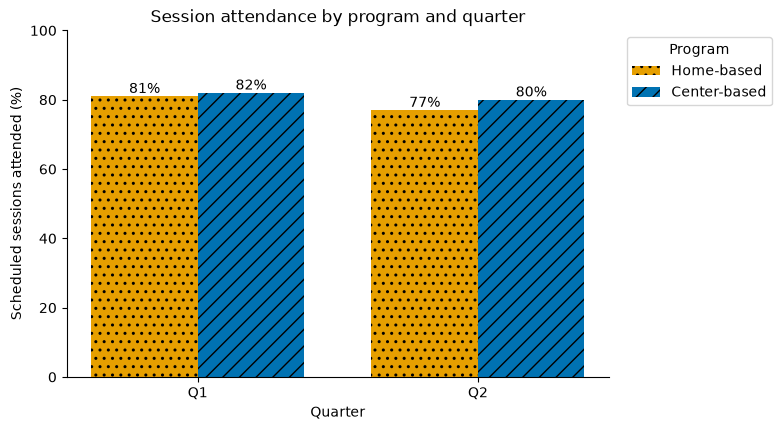

y-axis runs from 0.0 to 100.0


In [9]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(
    x - width / 2, home, width,
    label="Home-based", color=ORANGE, hatch=".."
)

center_bars = redesign_ax.bar(
    x + width / 2, center, width,
    label="Center-based", color=BLUE, hatch="//"
)

redesign_ax.bar_label(home_bars, fmt="%d%%")
redesign_ax.bar_label(center_bars, fmt="%d%%")

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_ylim(0, 100)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Session attendance by program and quarter")

redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

redesign_ax.legend(
    title="Program",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [10]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = "How do the achievement rates of weekly exercise goals differ between home-based and center-based rehabilitation programs across 4 follow up visits?"
audience = "The rehabilitation program coordinator will use the chart to decide if there needs to be additional follow ups."
intended_claim = "At visit 4, 79% of center based patients met the exercise goal compared to the 70% of home based patients."
y_measure = "Percentage of patients seen who met the weekly 150 minute exercise goal (%)."
grain = "One rehabilitation program at one follow-up visit."  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[
    ["program", "visit_number", "goal_met_pct"]
]

supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

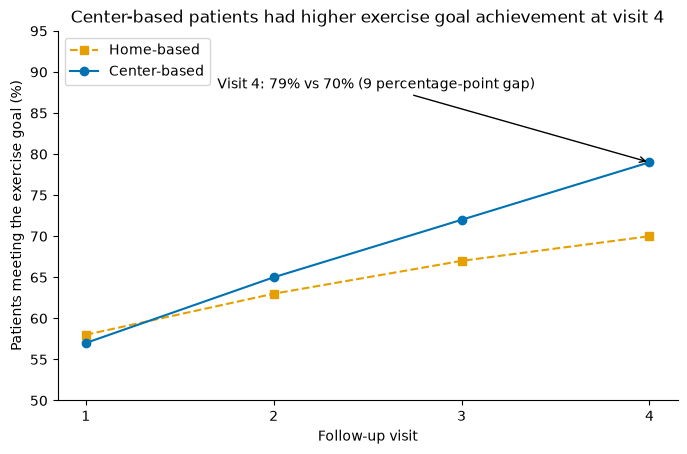

In [13]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE, marker="s", linestyle="--",
    label="Home-based"
)

explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE, marker="o", linestyle="-",
    label="Center-based"
)

explanatory_ax.annotate(
    "Visit 4: 79% vs 70% (9 percentage-point gap)",
    xy=(4, 79),
    xytext=(1.7, 88),
    arrowprops={"arrowstyle": "->"}
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_ylim(50, 95)
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_title("Center-based patients had higher exercise goal achievement at visit 4")

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)
explanatory_ax.legend()

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [14]:
text_alternative = (
    "The line chart shows the percentage of patients meeting their weekly "
    "150-minute exercise goal across four follow-up visits. The x-axis shows "
    "the follow-up visit number, and the y-axis shows the percentage of patients "
    "meeting the goal. Home-based patients increased from 58% at visit 1 to "
    "70% at visit 4, while center-based patients increased from 57% to 79%. "
    "At visit 4, center-based patients had a 9-percentage-point higher rate "
    "(79% versus 70%). Patients chose their program, so this does "
    "not establish causation. Each percentage also includes only patients "
    "seen at that visit, which is approximately 45 per program, so the difference "
    "could be due to random variation or differences in the patients who returned."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?

A reader would be able to tell them apart in greyscale because the bar chart uses different hatch patterns while the line chart uses different markers and line styles.

2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?

The explanatory chart's explanation points to the center-based program at visit 4, which is 79%, and it correctly identifies the 9 percentage point difference compared with the home-based program, which is 70%, without implying causation.

3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?

There was no text cut off or overlapping in either saved chart so no changes were needed.

4. What limitation remains that no chart design can fix?

The limitation remaining is the fact that the patients chose their own rehailitation programs so it is impossible to determine whether the programs actually caused the observed differences. Also the small sample size of 12 patients and any differences in which patients returned for follow up could strongly influence the outcomes.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()